## Exploratory Data Analysis
### 6,278 Exoplanets: What the Data Reveals About Worlds Beyond Our Solar System

---

Data: [`exoplanetdata`](https://github.com/moderndive/exoplanetdata) (ModernDive, 2026), a classroom snapshot of the [NASA Exoplanet Archive](https://exoplanetarchive.ipac.caltech.edu/) table of confirmed planets. It has one row per planet, including the planets discovered so far in 2026. The data is provided as `exoplanets_2026.csv`; keep it in the same folder as this notebook (in Google Colab, upload it with the folder icon on the left).

An **exoplanet** is a planet that orbits a star other than our Sun. The first ones were confirmed in the 1990s; today there are thousands.

### In this notebook

1. What is EDA? Purpose and the EDA workflow
2. Understanding the dataset: structure, data types and summary statistics
3. Data quality checks: missing values, duplicates and inconsistent data
4. Univariate analysis: distributions, histograms and box plots
5. Bivariate analysis: scatter plots, correlation and relationships between variables
6. Drawing insights: summarizing findings and communicating results

ie. The sections follow the general EDA workflow: first **what** is in the data, then whether we can **trust** it, then one column at a time, then two columns at a time, and finally what we **learned**.

**Data Stories:** 1 Most Exoplanets Have Never Been Seen, 2 Hot Jupiters: The Planets Nobody Expected.

**How to use this notebook:** in this class **you** find the insights.

- **Zoom chat:** post your Predict guesses, Your turn answers and insights in the Zoom chat, so we can compare them as a class.
- **Predict:** before running the next cell, write down your guess. Then run it and compare.
- **Your turn:** a question about the data. Write the code in the empty cell below it. Open **Hint** if you are stuck, and **Answer** only to check your result.
- **Change and rerun:** some cells start with a setting in CAPITALS. Change it and run the cell again.
- **Insight:** stays hidden until you have answered the questions. Write your own one-sentence insight first, then compare.
- **Exercise:** homework, to finish after class.

## 1. What is EDA? Purpose and the EDA Workflow

**Exploratory Data Analysis (EDA)** means getting to know a dataset before you build any model: what is in it, whether it can be trusted, and what patterns it holds.

**The EDA workflow:**

1. Set expectations: what should the data look like?
2. Load the data and run sanity checks.
3. Inspect and clean: missing values, duplicates, impossible values.
4. Explore one variable at a time, then pairs of variables.
5. Visualize what you find.
6. Summarize the insights and choose candidate features.

|  | Numbers | Charts |
|---|---|---|
| **One variable** | mean, median, counts | histogram, box plot, bar chart |
| **Two variables** | correlation, group summaries | scatter plot, heat map |

## 2. Understanding the Dataset: Structure, Data Types and Summary Statistics

The columns we will use most (Earth and Jupiter are given for comparison):

| Column | Meaning | Earth | Jupiter |
|---|---|---|---|
| `discovery_method` | how the planet was found | | |
| `discovery_year` | year it was announced | | |
| `orbital_period_days` | length of its year, in days | 365 | 4,333 |
| `semi_major_axis_au` | distance from its star (AU = Earth-Sun distance) | 1 | 5.2 |
| `radius_earth` | size, Earth = 1 | 1 | 11.2 |
| `mass_earth` | mass, Earth = 1 | 1 | 318 |
| `eq_temp_k` | estimated temperature in Kelvin (K) | 255 | 110 |
| `distance_pc` | distance from us in parsecs (1 pc = 3.26 light years) | | |

**Expectations:** about 6,000 rows (one per planet), no duplicate planet names, positive sizes and masses, and discovery years between the 1990s and 2026.

**A simple way to picture this data:** think of a giant box of trading cards, **one card per planet**. Each card lists facts about that planet: its name, size, weight, temperature, how long its year is, and how it was found. In this notebook we sort, count and draw pictures of those cards.

We first open our toolboxes (pandas for tables, matplotlib and seaborn for drawing), then load the data. `.head()` shows the first 5 rows.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

planets_raw = pd.read_csv("exoplanets_2026.csv")
planets_raw.head()

,planet_name,host_name,n_stars,n_planets,discovery_method,discovery_year,discovery_facility,orbital_period_days,semi_major_axis_au,eccentricity,...,star_spec_type,star_temp_k,star_radius_solar,star_mass_solar,star_metallicity_dex,star_log_g,star_age_gyr,ra_deg,dec_deg,distance_pc
0,11 Com b,11 Com,2.0,1.0,Radial Velocity,2007.0,Xinglong Station,323.21000,1.178,0.2380,...,G8 III,4874.0,13.76,2.09,-0.26,2.45,NaN,185.178779,17.793252,93.1846
1,11 UMi b,11 UMi,1.0,1.0,Radial Velocity,2009.0,Thueringer Landessternwarte Tautenburg,516.21997,1.530,0.0800,...,K4 III,4213.0,29.79,2.78,-0.02,1.93,1.56,229.274595,71.823943,125.3210
2,14 And b,14 And,1.0,1.0,Radial Velocity,2008.0,Okayama Astrophysical Observatory,186.76000,0.775,0.0000,...,K0 III,4888.0,11.55,1.78,-0.21,2.55,4.50,352.824150,39.235837,75.4392
3,14 Her b,14 Her,1.0,2.0,Radial Velocity,2002.0,W. M. Keck Observatory,1766.41000,2.839,0.3683,...,K0,5338.0,0.93,0.97,0.43,4.45,4.60,242.602101,43.816362,17.9323
4,HD 145675 c,14 Her,1.0,2.0,Radial Velocity,2021.0,Multiple Observatories,15732.45889,20.000,0.5200,...,K0,5338.0,0.93,0.97,0.43,4.45,4.60,242.602101,43.816362,17.9323


In [ ]:
planets_raw.columns

Index(['planet_name', 'host_name', 'n_stars', 'n_planets', 'discovery_method',
       'discovery_year', 'discovery_facility', 'orbital_period_days',
       'semi_major_axis_au', 'eccentricity', 'inclination_deg', 'radius_earth',
       'radius_jupiter', 'mass_earth', 'mass_jupiter', 'density_g_cm3',
       'eq_temp_k', 'insolation_earth', 'star_spec_type', 'star_temp_k',
       'star_radius_solar', 'star_mass_solar', 'star_metallicity_dex',
       'star_log_g', 'star_age_gyr', 'ra_deg', 'dec_deg', 'distance_pc'],
      dtype='str')

**Sanity checks:** look at a few random rows too (the first rows are not always typical), then check the shape and the data types.

In [ ]:
planets_raw.sample(5, random_state=42) #recall this from previous week using np.rand

,planet_name,host_name,n_stars,n_planets,discovery_method,discovery_year,discovery_facility,orbital_period_days,semi_major_axis_au,eccentricity,...,star_spec_type,star_temp_k,star_radius_solar,star_mass_solar,star_metallicity_dex,star_log_g,star_age_gyr,ra_deg,dec_deg,distance_pc
4386,Kepler-615 b,Kepler-615,1.0,1.0,Transit,2016.0,Kepler,10.355847,0.08500,0.0,...,NaN,4655.0,0.690,0.73,-0.07,4.620,3.72,282.450693,46.321367,330.000
4233,Kepler-511 b,Kepler-511,1.0,2.0,Transit,2016.0,Kepler,296.637865,0.85672,0.0,...,NaN,5770.0,1.200,1.00,0.01,4.280,7.94,282.945538,47.574918,651.999
2873,Kepler-1530 c,Kepler-1530,1.0,3.0,Transit,2016.0,Kepler,5.322741,0.05744,0.0,...,NaN,5477.0,0.880,0.92,0.03,4.520,4.27,288.162440,48.165153,489.876
4747,Kepler-889 b,Kepler-889,1.0,1.0,Transit,2016.0,Kepler,3.744439,0.04975,0.0,...,NaN,5961.0,1.250,1.14,0.19,4.300,3.98,291.467454,50.759560,598.313
3167,Kepler-1753 b,Kepler-1753,1.0,1.0,Transit,2021.0,Kepler,16.004601,0.11790,0.0,...,NaN,5180.0,0.769,0.86,0.00,4.597,6.20,288.236664,46.605874,707.688


**Predict:** how many rows and columns does the data have? What data type do you expect `discovery_year` to be?

In [ ]:
print("Shape:", planets_raw.shape)
planets = planets_raw.copy()           # keep the raw data untouched
planets.dtypes

Shape: (6278, 28)


planet_name                 str
host_name                   str
n_stars                 float64
n_planets               float64
discovery_method            str
discovery_year          float64
discovery_facility          str
orbital_period_days     float64
semi_major_axis_au      float64
eccentricity            float64
inclination_deg         float64
radius_earth            float64
radius_jupiter          float64
mass_earth              float64
mass_jupiter            float64
density_g_cm3           float64
eq_temp_k               float64
insolation_earth        float64
star_spec_type              str
star_temp_k             float64
star_radius_solar       float64
star_mass_solar         float64
star_metallicity_dex    float64
star_log_g              float64
star_age_gyr            float64
ra_deg                  float64
dec_deg                 float64
distance_pc             float64
dtype: object

**Question:** `discovery_year` should be a whole number, but its type is `float64` (2007.0 instead of 2007). Why? One planet has no year recorded, and pandas stores a missing value (`NaN`) as a decimal number, which turns the whole column into decimals. We convert it to pandas' `Int64` type, which allows whole numbers and missing values together.

Recall from week 2 about dtype precedence.

In [ ]:
planets["discovery_year"] = planets["discovery_year"].astype("Int64")
print("Missing years:", planets["discovery_year"].isnull().sum())
print("Year range:", planets["discovery_year"].min(), "to", planets["discovery_year"].max())

Missing years: 1
Year range: 1992 to 2026


**What this cell does:** a summary for every number column: how many rows have a value, the average, the smallest, the biggest and the middle value.

In [ ]:
planets.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
n_stars,6278.0,1.101465,0.339706,1.0,1.0,1.0,1.0,4.0
n_planets,6278.0,1.75884,1.149137,1.0,1.0,1.0,2.0,8.0
discovery_year,6277.0,2017.174287,5.078312,1992.0,2014.0,2016.0,2021.0,2026.0
orbital_period_days,5938.0,72082.202099,5219262.249991,0.090706,4.303691,10.684574,38.05025,402000000.0
semi_major_axis_au,5850.0,15.686887,348.566097,0.0044,0.0523,0.10205,0.305675,19000.0
eccentricity,5227.0,0.079298,0.152944,0.0,0.0,0.0,0.0905,0.95
inclination_deg,4766.0,86.538867,12.026354,0.1865,86.84,88.7,89.61,176.092
radius_earth,6228.0,5.809693,5.404283,0.3098,1.84,2.846633,11.9,87.20587
radius_jupiter,6228.0,0.518337,0.482176,0.027639,0.164154,0.25383,1.06,7.78
mass_earth,6247.0,401.434273,1138.752045,0.02,4.27,9.2,184.182023,9534.85221


**What to notice in `describe()`:**

- The **mean** orbital period is about 72,000 days, but the **median** (`50%`) is under 11 days. When the mean is far above the median, a few very large values are pulling it up.
- `count` differs between columns: some columns are missing many values. We look at this in Section 3.

**Your turn 1:** how many planets were discovered in 2026 so far? Which year had the most discoveries?

<details>
  <summary>Hint</summary>
  
  `(planets["discovery_year"] == 2026).sum()` and `value_counts()`
  
</details>

<details>
  <summary>Answer</summary>
  
  192 planets so far in 2026. The record year is 2016, with 1,496 planets, when the Kepler team confirmed a huge batch at once.
  
</details>

In [ ]:
# Your turn

**Your turn 2:** which telescope or observatory (`discovery_facility`) has found the most planets?

<details>
  <summary>Hint</summary>
  
  `value_counts()` on the `discovery_facility` column, then `.head()`
  
</details>

<details>
  <summary>Answer</summary>
  
  Kepler, with 2,784 planets, followed by TESS (885) and K2 (549). Space telescopes found most known exoplanets.
  
</details>

In [ ]:
# Your turn

**Change and rerun:** every row is one planet's "card". Type any planet name into `PLANET` and run the cell to see its card. Start with **51 Peg b**, the first planet ever found around a Sun-like star. We will meet it again in Data Story 2.

<details>
  <summary>Hint</summary>
  
  `planets.sample(random_state=<some int>)`
  
</details>

In [ ]:
PLANET = "51 Peg b"          # change me
planets.loc[planets["planet_name"] == PLANET].T

,34
planet_name,51 Peg b
host_name,51 Peg
n_stars,1.0
n_planets,1.0
discovery_method,Radial Velocity
discovery_year,1995
discovery_facility,Haute-Provence Observatory
orbital_period_days,4.230785
semi_major_axis_au,0.0527
eccentricity,0.013


## 3. Data Quality Checks: Missing Values, Duplicates and Inconsistent Data

In [ ]:
print("Duplicate rows:", planets.duplicated().sum())
print("Duplicate planet names:", planets["planet_name"].duplicated().sum())

missing = planets.isnull().mean().mul(100).round(1).sort_values(ascending=False)
missing.head(10)                       # percent missing, worst columns first

Duplicate rows: 0
Duplicate planet names: 0


star_spec_type          63.1
insolation_earth        29.9
eq_temp_k               25.5
inclination_deg         24.1
star_age_gyr            22.7
eccentricity            16.7
star_metallicity_dex    10.2
semi_major_axis_au       6.8
orbital_period_days      5.4
star_log_g               5.1
dtype: float64

### Data Story 1 Most Exoplanets Have Never Been Seen

Only one discovery method, **imaging**, actually takes a picture of a planet. Every other method detects a planet through its effect on its star's light: a tiny dip, a wobble, or a brief brightening. So what happens to the columns that cannot be measured?

**Predict:** what share of all these planets do you think were actually photographed?

**Your turn 3:** what share of planets were found by imaging?

<details>
  <summary>Hint</summary>
  
  `(planets["discovery_method"] == "Imaging")` is True for imaging planets; the `.mean()` of True/False values is a share.
  
</details>

<details>
  <summary>Answer</summary>
  
  Only 1.5% (97 planets). Every other planet was detected indirectly, through its star.
  
</details>

In [ ]:
# Your turn

**What this cell does:** how many planets share each exact temperature. In Google Colab, hover over the column name to see a quick chart of it.

In [ ]:
#hover over me!
planets.eq_temp_k.value_counts()

eq_temp_k
1000.0    12
938.0     10
401.0     10
786.0     10
543.0     10
          ..
471.2      1
410.3      1
356.7      1
1900.0     1
448.1      1
Name: count, Length: 1906, dtype: int64

**Predict:** which discovery method do you think has the **most** missing temperatures: Transit, Radial Velocity, Microlensing or Imaging?

1. `main.groupby("discovery_method", observed=True)["eq_temp_k"]`
- `groupby("discovery_method")`: This splits planets into separate groups based on the unique values in the discovery_method column.
- `observed=True`: This lets us only show categories that actually appear in the data (relevant if discovery_method is a categorical column with unused categories).
- `["eq_temp_k"]`: After grouping, this selects only the `eq_temp_k` (equilibrium temperature) column for further calculation. Any operation after this will only look at the temperature values within each discovery group.
2. `.apply(lambda s: s.isnull().mean() * 100)`
This is where the calculation happens, `.apply()` function runs the custom lambda function on each group's temperature series:

- `s.isnull()`: Returns a Series of boolean values (True for missing values, False for known values).
- `.mean()`: Since Python treats True as 1 and False as 0, taking the mean (average) of these booleans calculates the fraction of values that are missing.
- `* 100`: Converts the decimal fraction into a percentage (e.g., 0.05 becomes 5.0%).
3. `.reindex(MAIN_METHODS)`
By default, the result might sort the discovery methods alphabetically. .reindex(MAIN_METHODS) rearranges the resulting index so it matches the specific order defined in your MAIN_METHODS list: ['Transit', 'Radial Velocity', 'Microlensing', 'Imaging'].

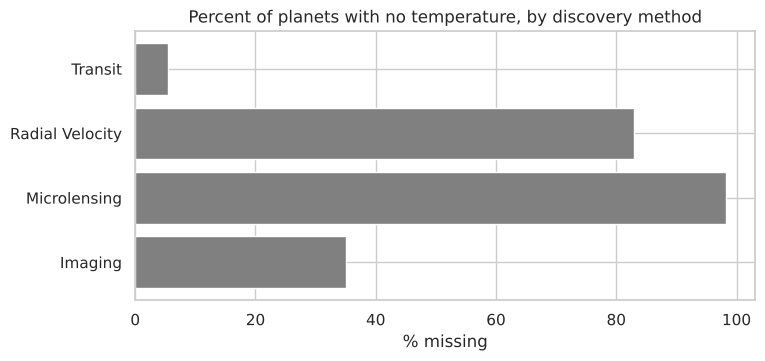

discovery_method
Transit             5.0
Radial Velocity    83.0
Microlensing       98.0
Imaging            35.0
Name: eq_temp_k, dtype: float64

In [ ]:
MAIN_METHODS = ["Transit", "Radial Velocity", "Microlensing", "Imaging"]
main = planets[planets["discovery_method"].isin(MAIN_METHODS)]

missing_by_method = (main.groupby("discovery_method", observed=True)["eq_temp_k"]
                         .apply(lambda s: s.isnull().mean() * 100)
                         .reindex(MAIN_METHODS))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(MAIN_METHODS, missing_by_method, color="gray")
ax.set(title="Percent of planets with no temperature, by discovery method", xlabel="% missing")
ax.invert_yaxis()
plt.show()
missing_by_method.round(0)

#### What should we do with the gaps?

| Option | Code | Risk |
|---|---|---|
| Drop the rows | `dropna()` | we lose data |
| Fill with one value | `fillna(median)` | can be badly wrong for some groups |
| Fill using a related column | `groupby(...).transform("median")` | better, but still a guess |
| Keep the gap and flag it | a new True/False column | none: the gap stays visible |

**Your turn 4:** microlensing planets are missing almost all their temperatures. Are they close to their star (hot) or far away (cold)? Compare the median `semi_major_axis_au` (distance from the star, Earth = 1) for each method. Would filling their gaps with the overall median temperature be fair?

<details>
  <summary>Hint</summary>
  
  Use `main.groupby("discovery_method")["semi_major_axis_au"].median()`, and `planets["eq_temp_k"].median()` for the overall median.
  
</details>

<details>
  <summary>Answer</summary>
  
  Microlensing planets typically sit about 2.3 AU from their star, about 30 times farther out than transit planets (0.08 AU), so they are cold. The overall median temperature is 823 K, which would make them far too hot. Better to **flag** the gaps than fill them.
  
</details>

In [ ]:
# Your turn

**What this cell does:** we put a sticker on every planet with a blank temperature, so we never forget it was blank.

In [ ]:
planets["temp_missing"] = planets["eq_temp_k"].isnull()       # flag, do not hide
planets["temp_missing"].value_counts()

temp_missing
False    4677
True     1601
Name: count, dtype: int64

#### Missing values can also hide

Radial velocity finds a planet by measuring how its star wobbles, which never shows the planet's size. Yet almost every planet has a radius. Where do those radii come from?

**Predict:** one of the two charts below shows real measurements and the other does not. Which one, and how can you tell?

Planets with no radius: 50


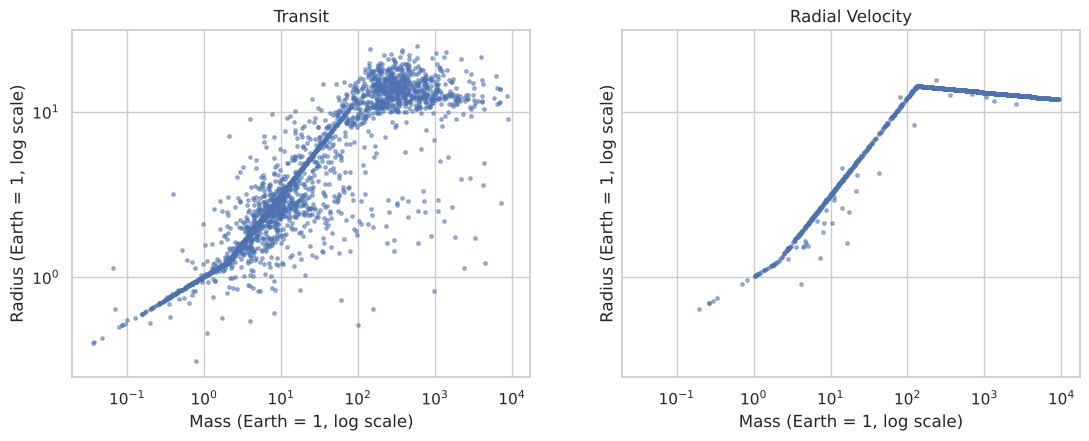

Transit: 571 giant planets, 465 different radius values
Radial Velocity: 639 giant planets, 29 different radius values


In [ ]:
METHOD = "Radial Velocity"          # change me: try "Microlensing" or "Imaging"

print("Planets with no radius:", planets["radius_earth"].isnull().sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, sharey=True)
for ax, method in zip(axes, ["Transit", METHOD]):
    subset = planets[planets["discovery_method"] == method]
    ax.scatter(subset["mass_earth"], subset["radius_earth"], s=6, alpha=0.5)
    ax.set(xscale="log", yscale="log", title=method,
           xlabel="Mass (Earth = 1, log scale)", ylabel="Radius (Earth = 1, log scale)")
plt.show()

# giant planets (heavier than 200 Earths): how many DIFFERENT radius values does each method report?
giants = planets[planets["mass_earth"] > 200]
for method in ["Transit", METHOD]:
    sizes = giants.loc[giants["discovery_method"] == method, "radius_earth"].dropna()
    print(f"{method}: {len(sizes)} giant planets, {sizes.nunique()} different radius values")

**Your turn 5:** change `METHOD` to `"Microlensing"` and rerun the cell above. Were microlensing radii measured, or filled in?

<details>
  <summary>Hint</summary>
  
  Look for two signs: do the dots fall on a neat line, and do many giant planets share the same few radius values? Compare with Transit.
  
</details>

<details>
  <summary>Answer</summary>
  
  Filled in. The dots follow the same neat line as radial velocity, and 134 microlensing giants share only 22 different radius values (571 transit giants have 465).
  
</details>

**Your turn 6:** a planet's `eccentricity` says how oval its orbit is (0 = a perfect circle). How many of the known eccentricity values are **exactly** 0? What might a 0 really mean?

<details>
  <summary>Hint</summary>
  
  Drop the missing values first with `.dropna()`, then count `== 0` with `.sum()` and take the share with `.mean()`.
  
</details>

<details>
  <summary>Answer</summary>
  
  3,075 of 5,227 known values (59%) are exactly 0. Perfect circles are rare in nature: many papers simply **assume** a circular orbit when they cannot measure it, so a 0 often means "not measured".
  
</details>

In [ ]:
# Your turn

**Write your insight:** in one sentence, what did these questions teach you about missing values in this dataset?

#### Insight:

<details>
  <summary>Reveal after you finish the Your turn questions above</summary>
  
  - Only 1.5% of planets were photographed. Everything else was inferred from starlight, so many columns cannot be measured directly.
- Temperature is missing for 5% of transit planets but 98% of microlensing planets: the gaps depend on **how** a planet was found. Microlensing planets are far from their star and cold, so one overall average would be badly wrong. We flag the gaps instead.
- Missing values also hide: radial velocity and microlensing radii sit on a formula line, and 59% of eccentricities are exactly 0. They look like measurements but are filled-in values.

**From domain knowledge:** microlensing detects a planet from a brief brightening of a distant star, which reveals little about the host star. The NASA archive fills in missing radii with a formula based on mass.
  
</details>

#### Goal: before filling missing values, check **why** they are missing, because when gaps depend on another column, one overall average gives wrong answers. Also remember that missing data does not always show up as `NaN`: values filled in with a formula or a default look real, so watch for patterns that are too perfect.

### Exercise 1 Investigate the Missing Values

1. Make the same "percent missing by method" chart for `insolation_earth` (the starlight a planet receives). Is the pattern similar?
2. Which discovery method has the highest share of eccentricities that are exactly 0?
3. `star_spec_type` is the column missing most often. Do its gaps also depend on the discovery method?

<details>
  <summary>Hints</summary>
  
  1. Copy the `missing_by_method` cell and change `"eq_temp_k"` to `"insolation_earth"`.
2. Keep only rows with a known eccentricity, then group `(planets["eccentricity"] == 0)` by `planets["discovery_method"]` and take the `.mean()`.
3. Use `.isnull()` in the same pattern.
  
</details>

In [ ]:
# Your code here

## 4. Univariate Analysis: Distributions, Histograms and Box Plots

**Skew** measures how lopsided a distribution is: 0 is symmetric, a large positive number means a long tail of large values.

In [ ]:
num_cols = ["orbital_period_days", "radius_earth", "mass_earth", "eq_temp_k", "distance_pc"]
summary = planets[num_cols].describe().T[["mean", "50%", "min", "max"]]
summary["skew"] = planets[num_cols].skew()
summary.round(1)

,mean,50%,min,max,skew
orbital_period_days,72082.2,10.7,0.1,402000000.0,76.9
radius_earth,5.8,2.8,0.3,87.2,1.8
mass_earth,401.4,9.2,0.0,9534.9,4.4
eq_temp_k,914.7,823.0,34.0,4050.0,1.1
distance_pc,705.0,364.0,1.3,8500.0,4.0


**Predict:** Earth's year is 365 days. Is the median exoplanet year longer or shorter? Write down a number.

**What this cell does:** two histograms of the same column. On the left, a normal scale. On the right, a log scale, which counts in jumps of 10 (1, 10, 100, 1,000 days).

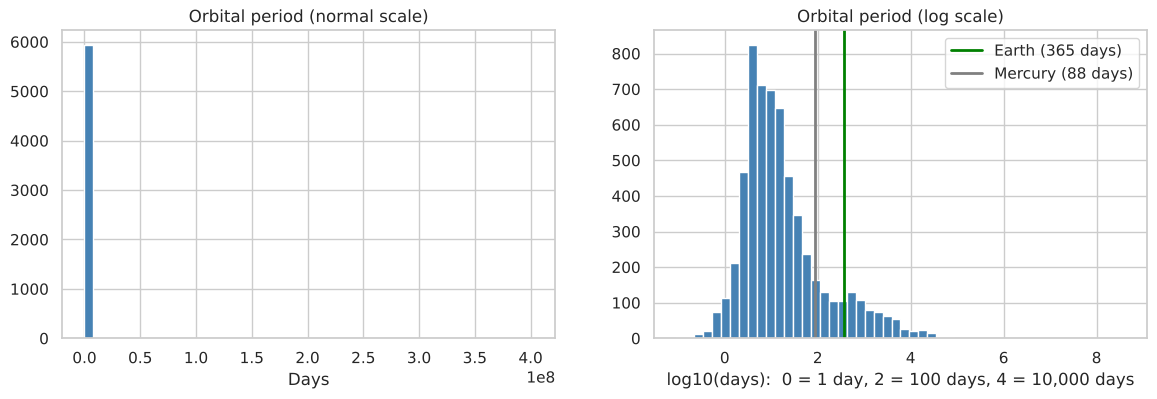

In [ ]:
period = planets["orbital_period_days"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(period, bins=50, color="steelblue")
axes[0].set(title="Orbital period (normal scale)", xlabel="Days")

axes[1].hist(np.log10(period), bins=50, color="steelblue")
axes[1].axvline(np.log10(365.25), color="green", linewidth=2, label="Earth (365 days)")
axes[1].axvline(np.log10(88), color="gray", linewidth=2, label="Mercury (88 days)")
axes[1].set(title="Orbital period (log scale)", xlabel="log10(days):  0 = 1 day, 2 = 100 days, 4 = 10,000 days")
axes[1].legend()
plt.show()

**Your turn 7:** what is the median exoplanet year, and what share of planets have a shorter year than Mercury's 88 days? Was your prediction close?

<details>
  <summary>Hint</summary>
  
  `period.median()`, and `(period < 88).mean()` for the share.
  
</details>

<details>
  <summary>Answer</summary>
  
  The median is 10.7 days, and 83% of planets have a shorter year than Mercury: about four out of five. The longest year (402 million days) is what squashes the left chart into one bar.
  
</details>

In [ ]:
# Your turn

**Your turn 8:** change `bins=50` in the right-hand chart to `bins=10`, then to `bins=200`, and rerun. Which number of bins tells the story best?

<details>
  <summary>Hint</summary>
  
  With too few bins, the single peak and the long right tail blur together. With too many, the bars get noisy.
  
</details>

<details>
  <summary>Answer</summary>
  
  There is no single right answer, but somewhere around 30 to 60 bins shows one clear peak (a few days) and a long tail to the right. 10 bins hides the shape; 200 bins makes it noisy.
  
</details>

**Predict:** in the box plot below, which method's box will sit furthest to the right (the biggest planets)?

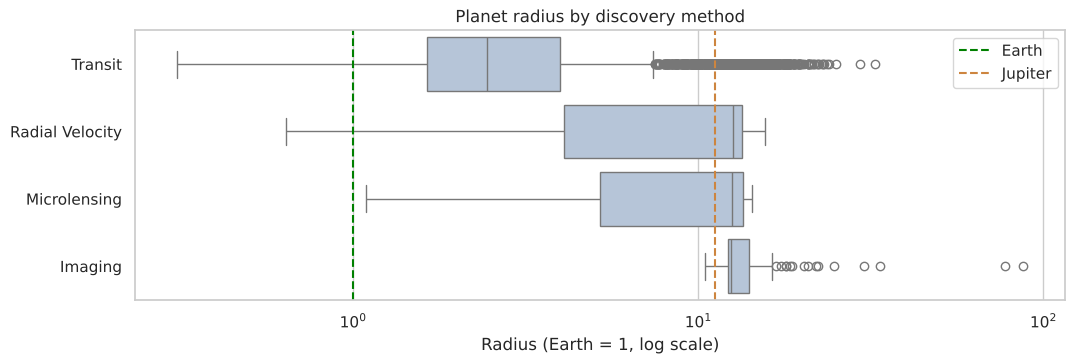

In [ ]:
fig, ax = plt.subplots(figsize=(12, 3.5))
sns.boxplot(data=main, x="radius_earth", y="discovery_method", order=MAIN_METHODS, color="lightsteelblue", ax=ax)
ax.axvline(1, color="green", linestyle="--", label="Earth")
ax.axvline(11.2, color="peru", linestyle="--", label="Jupiter")
ax.set(xscale="log", title="Planet radius by discovery method", xlabel="Radius (Earth = 1, log scale)", ylabel="")
ax.legend()
plt.show()

**Your turn 9:** transit planets range from smaller than Earth to bigger than Jupiter. Why is the radial velocity box so squashed at the top? Print Q1, the median, Q3 and the largest radius for each method to check.

<details>
  <summary>Hint</summary>
  
  `main.groupby("discovery_method")["radius_earth"].describe()` gives all of these at once. Think back to Data Story 1.
  
</details>

<details>
  <summary>Answer</summary>
  
  The radial velocity box is not narrow overall (it runs from about 4 to 13 Earth radii), but its top half is squashed: the median (12.6) sits almost on top of Q3 (13.4), and no radial velocity planet is bigger than about 16 Earths. Transit planets, in contrast, reach more than 30 Earths.

This happens because of Data Story 1 (missing values can also hide). Radial velocity mostly finds heavy planets, and their sizes were never measured: they were filled in with a formula. For heavy planets, that formula always gives a size close to Jupiter's, so hundreds of planets pile up in the same small range and there are no outliers above it. Real measurements, like the transit ones, spread out much more.
  
</details>

In [ ]:
# Your turn

### Exercise 2 Distributions

1. Plot a histogram of `distance_pc`, first on a normal scale and then with `np.log10`. Which is easier to read?
2. Plot a histogram of `eq_temp_k`. Mark Earth (255 K) with `axvline`. What share of planets are hotter than Earth?

<details>
  <summary>Hints</summary>
  
  1. Copy the orbital period cell and swap in `planets["distance_pc"].dropna()`.
2. `(planets["eq_temp_k"] > 255).mean()` gives the share; remember that missing temperatures are not counted as hotter.
  
</details>

In [ ]:
# Your code here

## 5. Bivariate Analysis: Scatter Plots, Correlation and Relationships Between Variables

**Correlation (r)** measures how closely two numbers move together, from -1 (one goes up, the other goes down) to +1 (both go up together). Values near 0 mean no straight-line link. Because our columns are so skewed, we correlate their **logs**.


### Data Story 2 Hot Jupiters: The Planets Nobody Expected

Before 1995, astronomers expected giant planets to orbit far from their stars, like Jupiter, which takes 12 years per orbit. Then 51 Pegasi b was found: a giant planet with a year of about 4 days. We call planets like it **hot Jupiters**: bigger than 8 Earths, with a year shorter than 10 days.

**Predict:** will planets with shorter years be hotter or colder? Will r be positive or negative?

**What this cell does:** each dot is a planet: orbit length against temperature. Hot Jupiters are coloured red, and the title shows the correlation r.

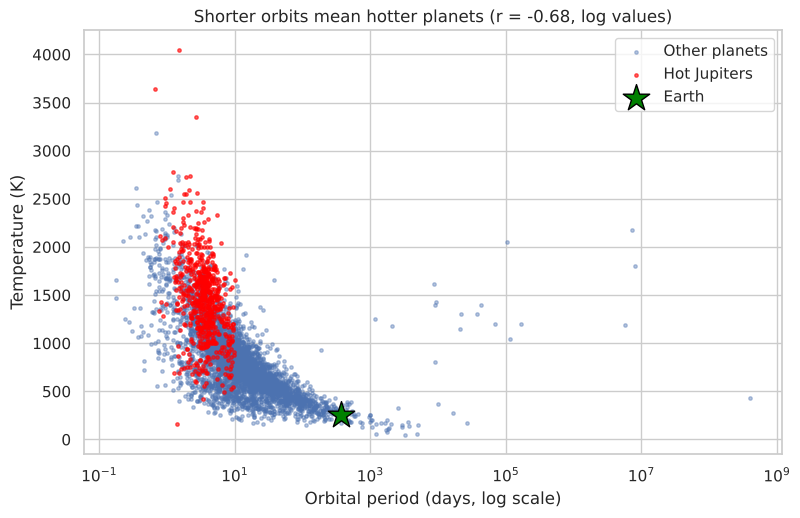

In [ ]:
planets["hot_jupiter"] = (planets["radius_earth"] > 8) & (planets["orbital_period_days"] < 10)

logs = np.log10(planets[["orbital_period_days", "eq_temp_k"]]).dropna()
r = logs["orbital_period_days"].corr(logs["eq_temp_k"])

hj = planets[planets["hot_jupiter"]]
others = planets[~planets["hot_jupiter"]]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(others["orbital_period_days"], others["eq_temp_k"], s=6, alpha=0.4, label="Other planets")
ax.scatter(hj["orbital_period_days"], hj["eq_temp_k"], s=6, alpha=0.6, color="red", label="Hot Jupiters")
ax.scatter(365.25, 255, marker="*", s=400, color="green", edgecolor="black", label="Earth", zorder=3)
ax.set(xscale="log", title=f"Shorter orbits mean hotter planets (r = {r:.2f}, log values)",
       xlabel="Orbital period (days, log scale)", ylabel="Temperature (K)")
ax.legend()
plt.show()

**Your turn 10:** how many hot Jupiters are there? What are their median temperature and median year length?

<details>
  <summary>Hint</summary>
  
  `hj` holds only the hot Jupiters. Use `len(hj)`, then `.median()` on `hj["eq_temp_k"]` and `hj["orbital_period_days"]`.
  
</details>

<details>
  <summary>Answer</summary>
  
  739 hot Jupiters, with a median temperature of 1,460 K (hotter than the melting point of copper) and a median year of just 3.5 days.
  
</details>

In [ ]:
# Your turn

**Your turn 11:** which planet is the hottest in the whole dataset, and how long is its year?

<details>
  <summary>Hint</summary>
  
  `planets.nlargest(1, "eq_temp_k")`, and show the `planet_name`, `eq_temp_k` and `orbital_period_days` columns.
  
</details>

<details>
  <summary>Answer</summary>
  
  KELT-9 b, at 4,050 K, with a year of only 1.5 days. That is hotter than the surface of many stars.
  
</details>

In [ ]:
# Your turn

**Your turn 12:** look up **51 Peg b** (the `PLANET` cell in Section 2, or `.loc`). What is its temperature in the data? What does that remind you of?

<details>
  <summary>Hint</summary>
  
  Check the `eq_temp_k` row of its card, and its `discovery_method`.
  
</details>

<details>
  <summary>Answer</summary>
  
  Its temperature is missing (`NaN`), and its radius (14.3 Earths) was filled in. The most famous hot Jupiter was found by radial velocity, so Data Story 1 applies to it too.
  
</details>

In [ ]:
# Your turn

A **correlation heat map** shows all pairs of columns at once. Red squares go up together, blue squares go in opposite directions, pale squares are barely linked.

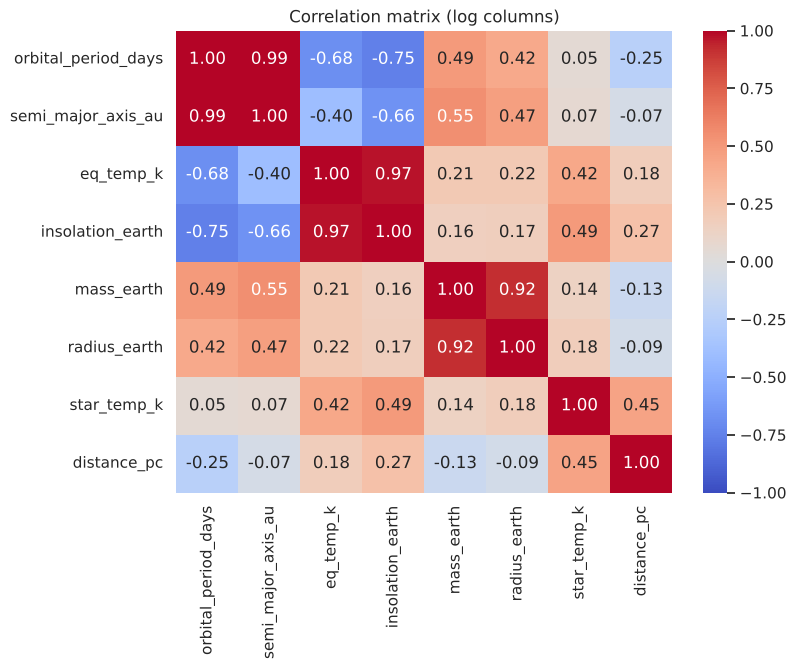

In [ ]:
pair_cols = ["orbital_period_days", "semi_major_axis_au", "eq_temp_k", "insolation_earth",
             "mass_earth", "radius_earth", "star_temp_k", "distance_pc"]
log_cols = np.log10(planets[pair_cols].where(planets[pair_cols] > 0))     # log of positive values only
corr_matrix = log_cols.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix (log columns)")
plt.show()

**Your turn 13:** in the heat map, which pair of different columns is linked almost perfectly, and which pair is closest to 0? What does each tell you?

<details>
  <summary>Hint</summary>
  
  Ignore the diagonal (every column is perfectly linked with itself). Look for the darkest red square and the palest square.
  
</details>

<details>
  <summary>Answer</summary>
  
  `orbital_period_days` and `semi_major_axis_au` are linked at 0.99: a bigger orbit always takes longer, so they carry the same information and a model only needs one. `orbital_period_days` and `star_temp_k` are closest to 0 (0.05): the length of a planet's year tells you almost nothing about how hot its star is.
  
</details>

**Write your insight:** in one sentence, what makes hot Jupiters so surprising?

#### Insight:

<details>
  <summary>Reveal after you finish the Your turn questions above</summary>
  
  - Planets with short orbits are much hotter (r = -0.68). The 739 hot Jupiters have a median year of 3.5 days and a median temperature of 1,460 K; KELT-9 b reaches 4,050 K.
- Correlation shows which columns carry the same information (period and orbit size, 0.99) and which are unrelated (period and star temperature, 0.05).

**From domain knowledge:** the discovery of 51 Pegasi b in 1995 won the 2019 Nobel Prize in Physics, because nobody expected giant planets so close to their stars.
  
</details>

#### Goal: study the relationship between two variables with a scatter plot and a correlation. We learn that the correlation (r) measures how strongly two columns move together and in which direction, why we use log values for skewed columns, and that highlighting one group (here, hot Jupiters) can turn a cloud of dots into a story.

### Exercise 3 Relationships

1. Draw a scatter plot of `mass_earth` against `radius_earth` for **transit planets only**, both axes on a log scale. Mark Earth and Jupiter.
2. Compute the correlation between log mass and log radius separately for transit and for radial velocity planets. Which is higher, and why does that **not** mean the radial velocity data is better?
3. Which hot Jupiter has the shortest year? Look up its card with the `PLANET` cell.

<details>
  <summary>Hints</summary>
  
  1. Filter with `planets[planets["discovery_method"] == "Transit"]`, then use `ax.set(xscale="log", yscale="log")`. Jupiter is 318 Earth masses and 11.2 Earth radii.
2. Take `np.log10` of the two columns for each method, then `.corr()`. Think about Data Story 1: what happens to a correlation when values come from a formula?
3. `hj.nsmallest(1, "orbital_period_days")`
  
</details>

In [ ]:
# Your code here

## 6. Drawing Insights: Summarizing Findings and Communicating Results

Good insights are short and backed by a number. Below, **you** fill in the evidence.

**Your turn 14:** replace each `?` with the number you found in today's Your turn questions, then run the cell.

<details>
  <summary>Hint</summary>
  
  Scroll back to your answers: Data Story 1 (imaging share, missing temperatures), Section 4 (median year) and Data Story 2 (hot Jupiters).
  
</details>

<details>
  <summary>Answer</summary>
  
  1.5% photographed; temperature missing for 98% of microlensing planets; a median year of 10.7 days; r = -0.68 and a median of 1,460 K for hot Jupiters.
  
</details>

In [ ]:
insights = pd.DataFrame([
    ("Most exoplanets have never been seen", "only ? were photographed"),
    ("Missing values depend on the discovery method", "temperature missing for ? of microlensing planets"),
    ("Most known planets finish a year in days", "median year of ? days"),
    ("Closer orbits mean hotter planets", "r = ?, hot Jupiters have a median of ? K"),
], columns=["Insight", "Evidence"])
insights

,Insight,Evidence
0,Most exoplanets have never been seen,only ? were photographed
1,Missing values depend on the discovery method,temperature missing for ? of microlensing planets
2,Most known planets finish a year in days,median year of ? days
3,Closer orbits mean hotter planets,"r = ?, hot Jupiters have a median of ? K"


### Summary (template)

- **Data:** 6,278 confirmed exoplanets (NASA Exoplanet Archive, 2026 snapshot), one row per planet.
- **Quality:** almost all planets were detected indirectly, so temperatures are missing mostly for non-transit planets (flagged, not filled with one average), and some radii and eccentricities are filled-in values.
- **Findings:** most known planets finish a year in days; close orbits mean hot planets, and hot Jupiters are the most extreme example.
- **Limitation:** this is not a random sample of the galaxy, so counts tell us what is **detectable**, not what is **common**.
- **Candidate features:** log orbital period, log radius, method (one-hot), starlight received, hot Jupiter flag.

### Exercise 4 Write an Executive Summary

Pick the insight you found most surprising. Write 3 to 5 sentences for a reader with no astronomy background, including one number and one limitation of the data. Add one chart whose title states the message.

<details>
  <summary>Hints</summary>
  
  Start with the finding, then the number, then the limitation. For the chart, reuse one from this notebook and change the title so it states your message, for example "Planets with shorter years are much hotter".
  
</details>

In [ ]:
# Your code here